# Семинар 11 [17-25-2]. Распределения в SciPy: документация и эксперименты

За 90 минут сравним шесть распределений в трёх лабораториях: проверка партии,
ошибки измерений и срок службы оборудования. Затем найдём ошибки в чужом коде
и самостоятельно решим новую задачу.

**Порядок работы:** документация → параметры и методы → ваш код → симуляция → вывод.
Какой закон подходит, какие у него параметры в SciPy и какими методами считать —
ищите в документации SciPy сами: в начале каждой лаборатории есть ссылки на страницы законов.
Перед кодом заполните короткую заметку.

Весь расчётный код пишете вы. Для каждой ячейки указано, какие структуры данных
нужно создать: их используют готовые функции для таблиц и графиков. Застряли — спросите преподавателя.

Графики и базовую обработку выборок выполняют готовые функции. Вы задаёте законы,
считаете вероятности и перцентили, создаёте выборки и объясняете результаты.
Все ситуации — авторские учебные эксперименты с заданными моделями, без подбора параметров.

**Запуск:** в Colab загрузите скачанный `.ipynb` через «Файл → Загрузить блокнот»,
сохраните копию на Диске и выполняйте ячейки по порядку (`Shift+Enter`).
После заполнения перезапустите среду и выполните всё сверху вниз.
Для незаполненных блоков готовые функции сообщат, каких результатов пока не хватает.

Датасеты скачивать не нужно. Для чтения документации и работы в Colab нужен интернет;
локально вычисления работают с заранее установленными NumPy, pandas, Matplotlib и SciPy.

## Маршрут на 90 минут

| Время | Действие |
|---|---|
| 0–8 | Ожидание, дисперсия, квантиль и перцентиль |
| 8–12 | Как устроена документация SciPy |
| 12–32 | Лаборатория 1: проверка партии |
| 32–50 | Лаборатория 2: ошибки измерения |
| 50–70 | Лаборатория 3: срок службы |
| 70–80 | Найдите ошибки |
| 80–88 | Самостоятельный перенос |
| 88–90 | Итоги и собственная шпаргалка |

Не успели — закончите дома.

## 0. Подготовка и короткий рекап

$E(X)$ — характеристика модели, среднее выборки — характеристика конкретных наблюдений.
$\mathrm{Var}(X)=E(X^2)-E(X)^2$, $\sigma(X)=\sqrt{\mathrm{Var}(X)}$.
Дисперсия имеет квадрат единиц исходной величины, стандартное отклонение — исходные единицы.

**Знак неравенства.** В курсе $F(x)=P(X<x)$, а в SciPy функция распределения — это $P(X\le x)$.
Для непрерывного закона разницы нет: вероятность отдельной точки нулевая.
Для целочисленной величины разница есть. Перед вызовом метода запишите событие
словами и проверьте, включена ли граница.

**Квантиль и перцентиль.** Квантиль уровня $q$ — порог, который величина не превышает
с вероятностью не меньше $q$ (берём наименьший такой порог).
Для непрерывного закона в квантиле $P(X\le x_q)$ ровно равна $q$.
Для дискретного закона это наименьшее целое $k$, для которого $P(X\le k)\ge q$:
равенства может не быть вовсе. **95-й перцентиль** — квантиль уровня $0{,}95$.

Спросите себя: достаточно ли среднего для оценки редкой большой ошибки?
Чем характеристика модели отличается от её оценки по 10 000 наблюдений?

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

rng = np.random.default_rng(2026)
SAMPLE_SIZE = 10_000
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

### Готовые функции

Выполните следующую ячейку один раз. Разбирать код рисования сейчас не требуется.

| Функция | Что ей передать | Что получите |
|---|---|---|
| `plot_laws` | Словарь «имя → созданный объект распределения» и настройки осей | PMF/PDF и CDF |
| `compare_samples` | Тот же словарь и словарь «имя → ваша выборка» | Выборки рядом с теоретическими кривыми |
| `summarize_samples` | Словарь выборок | Объём, среднее, дисперсию и стандартное отклонение выборки |
| `show_results` | Вашу таблицу: список словарей или DataFrame | Аккуратно оформленные результаты |

`summarize_samples` делит сумму квадратов отклонений на $n$, а не на $n-1$.
Теоретические характеристики, вероятности, условные частоты и перцентили вычисляете вы.
Имена моделей в словарях законов и выборок должны совпадать.

In [3]:
# @title Готовые функции для графиков и выборок (ячейку можно свернуть)
COLORS = ("#1F6BFF", "#6B7280")
LINESTYLES = ("-", "--")


def _sample_values(sample):
    values = np.asarray(sample, dtype=float)
    if values.ndim != 1 or values.size == 0 or not np.isfinite(values).all():
        raise ValueError("Нужна непустая одномерная выборка конечных чисел.")
    return values


def _ready(mapping, description):
    if mapping is None or len(mapping) == 0:
        print(f"Сначала заполните расчётную ячейку: {description}.")
        return False
    return True


def show_results(rows):
    """Показывает вашу таблицу результатов; сама ничего не считает."""
    if not _ready(rows, "таблица ваших результатов"):
        return
    frame = pd.DataFrame(rows).round(5)
    if len(frame.columns) <= 6:
        display(frame)
    else:
        for start in range(1, len(frame.columns), 5):
            display(frame.iloc[:, [0, *range(start, min(start + 5, len(frame.columns)))]] )


def summarize_samples(samples):
    """Среднее, дисперсия (делим на n) и стандартное отклонение выборок."""
    if not _ready(samples, "словарь выборок"):
        return pd.DataFrame()
    rows = []
    for name, sample in samples.items():
        values = _sample_values(sample)
        rows.append({
            "Модель": name,
            "Объём выборки": values.size,
            "Среднее выборки": values.mean(),
            "Дисперсия выборки (делим на n)": values.var(ddof=0),
            "Стандартное отклонение выборки": values.std(ddof=0),
        })
    return pd.DataFrame(rows)


def _grid(xlim, discrete):
    lower, upper = xlim
    if discrete:
        return np.arange(np.floor(lower), np.ceil(upper) + 1, dtype=int)
    return np.linspace(lower, upper, 700)


def _decorate(axes, xlim, xlabel, density_label, discrete, thresholds):
    axes[0].set_title("Вероятности значений" if discrete else "Плотность")
    axes[0].set_ylabel("Вероятность" if discrete else density_label)
    axes[1].set_title("CDF: вероятность не превысить порог")
    axes[1].set_ylabel("Вероятность")
    axes[0].set_ylim(bottom=0)
    axes[1].set_ylim(-0.02, 1.02)
    for ax in axes:
        ax.set_xlim(*xlim)
        ax.set_xlabel(xlabel)
        for threshold in thresholds:
            ax.axvline(threshold, color="#374151", ls=":", lw=1.2,
                       label=f"Порог {threshold:g}")
        ax.legend(fontsize=9)


def plot_laws(laws, *, discrete, xlim, xlabel, density_label="Плотность", thresholds=()):
    """Рисует PMF/PDF и CDF переданных объектов распределений."""
    if not _ready(laws, "словарь объектов распределений"):
        return
    grid = _grid(xlim, discrete)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
    width = 0.8 / len(laws)
    for index, (name, law) in enumerate(laws.items()):
        color = COLORS[index % len(COLORS)]
        linestyle = LINESTYLES[index % len(LINESTYLES)]
        if discrete:
            offset = (index - (len(laws) - 1) / 2) * width
            axes[0].bar(grid + offset, law.pmf(grid), width=width,
                        color=color, alpha=0.75, label=name)
            axes[1].step(grid, law.cdf(grid), where="post", color=color,
                         ls=linestyle, lw=2, label=name)
        else:
            axes[0].plot(grid, law.pdf(grid), color=color, ls=linestyle,
                         lw=2, label=name)
            axes[1].plot(grid, law.cdf(grid), color=color, ls=linestyle,
                         lw=2, label=name)
    _decorate(axes, xlim, xlabel, density_label, discrete, thresholds)
    plt.show()


def compare_samples(laws, samples, *, discrete, xlim, xlabel,
                    density_label="Плотность", thresholds=()):
    """Сравнивает выборки с теоретическими PMF/PDF и CDF (эмпирическая CDF — P(X ≤ x))."""
    if not _ready(laws, "словарь объектов распределений"):
        return
    if not _ready(samples, "словарь выборок"):
        return
    if set(laws) != set(samples):
        raise ValueError("Имена моделей в словарях распределений и выборок должны совпадать.")
    grid = _grid(xlim, discrete)
    for index, (name, law) in enumerate(laws.items()):
        values = _sample_values(samples[name])
        color = COLORS[index % len(COLORS)]
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
        fig.suptitle(f"{name}: {values.size:,} наблюдений".replace(",", " "))
        if discrete:
            support, counts = np.unique(values, return_counts=True)
            axes[0].bar(support, counts / values.size, width=0.75,
                        color=color, alpha=0.4, label="Частоты в выборке")
            axes[0].plot(grid, law.pmf(grid), "o", ms=4,
                         color="#111827", label="Теоретические вероятности")
            ecdf_grid = grid
        else:
            axes[0].hist(values, bins=40, density=True, color=color,
                         alpha=0.4, label="Гистограмма выборки")
            axes[0].plot(grid, law.pdf(grid), color="#111827", lw=2,
                         label="Теоретическая плотность")
            visible = values[(values >= xlim[0]) & (values <= xlim[1])]
            ecdf_grid = np.unique(np.r_[xlim[0], visible, xlim[1]])
        ecdf_values = np.searchsorted(np.sort(values), ecdf_grid, side="right") / values.size
        axes[1].step(ecdf_grid, ecdf_values, where="post", color=color,
                     lw=1.7, label="Эмпирическая CDF")
        if discrete:
            axes[1].step(grid, law.cdf(grid), where="post", color="#111827",
                         ls="--", lw=1.5, label="Теоретическая CDF")
        else:
            axes[1].plot(grid, law.cdf(grid), color="#111827", ls="--",
                         lw=1.5, label="Теоретическая CDF")
        _decorate(axes, xlim, xlabel, density_label, discrete, thresholds)
        plt.show()

### Где искать

Вся работа идёт по документации [scipy.stats](https://docs.scipy.org/doc/scipy/reference/stats.html):
там список распределений, у каждого — своя страница с параметрами, методами и примерами.
Как это устроено, разберитесь сами. Небольшая демонстрация ниже: предскажите результат до запуска.

In [4]:
demo_law = stats.norm()
show_results([{
    "Пример": "Стандартный нормальный закон",
    "CDF в нуле": demo_law.cdf(0),
    "Квантиль уровня 0.5": demo_law.ppf(0.5),
}])

,Пример,CDF в нуле,Квантиль уровня 0.5
0,Стандартный нормальный закон,0.5,0.0


## 1. Проверка партии: независимость и выборка без возвращения

**Документация:** [binom](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html), [hypergeom](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.hypergeom.html).

**Условие.** В первой схеме независимо проверяют 10 изделий; каждое бракованное
с вероятностью 0,2. Во второй из партии 20 изделий, среди которых ровно 4
бракованных, случайно выбирают 10 без возвращения. $X$ — число бракованных
среди проверенных. Каждая повторная проверка второй схемы начинается с исходной партии.

**Заметка перед кодом — заполните своими словами.**

- Величина и возможные значения: … x=10, 1 партия или схема возможны значения 0<=x<= 10, вторая схема 0<=x<=4
- Первая схема: семейство, параметры и их смысл: … n=10 p=0.2 n-сколько проверяем брака, p- вер-ть брака, тут нужен binom биноминальный закон
- Вторая схема: семейство, параметры и их смысл: … n=4 M=20 N=10 n- сколько брака точно, M- сколько всего деталей и N- сколько деталей взяли без возв-ния, тут нужен hypergeom гипергеометрический закон
- Нужные методы и смысл их результатов: … .ppf(q) - обратная фунцуия распредления cdf(x)- плюсует все вероятности слева направо до точки, короче вот эту шляпу p( X<= x) mean()- мат ожидание e(x) var()- сколько сильно разбросаны значения вокруг среднего std() - корень от var(). тложе самое но просто корень для того чтобы единицы измерения совпадали

### 1.1. Анализ моделей

1. Создайте словарь `batch_laws`: имя модели → объект распределения SciPy.
2. Для каждой модели найдите $E(X)$, $\mathrm{Var}(X)$, $\sigma(X)$, $P(X\ge3)$ и $P(X<2)$.
3. Найдите 95-й перцентиль и покажите, что он наименьший: значения функции распределения
   SciPy в нём и в предыдущем целом.
4. Соберите таблицу `batch_results`.

**Структуры данных.**
- `batch_laws` — словарь: ключ — название модели (строка), значение — объект распределения SciPy с заданными параметрами.
- `batch_results` — список словарей: один словарь на модель, ключи — названия столбцов (первый — `"Модель"`), значения — числа. Из него `show_results` строит таблицу.

In [ ]:
# batch_laws = {"название модели": объект распределения, ...}
# batch_results = [{"Модель": ..., "E(X)": ..., ...}, ...]


In [5]:
batch_laws = {"Биномиальный": stats.binom(n=10, p=0.2), "Гипергеометрический": stats.hypergeom(M= 20, n=4, N= 10)}
batch_results = []
for name in batch_laws:
    law = batch_laws[name]
    p95 = int(law.ppf(0.95))
    row = { "Модель": name, "E(X)": law.mean(), "Var(X)": law.var(), "P(X >= 3)": 1 - law.cdf(2), "P(X < 2)": law.cdf(1),"95-й перцентиль": p95}
    batch_results.append(row)

,Модель,E(X),Var(X),P(X >= 3),P(X < 2),95-й перцентиль
0,Биномиальный,2.0,1.60000,0.32220,0.37581,4
1,Гипергеометрический,2.0,0.84211,0.29102,0.29102,3


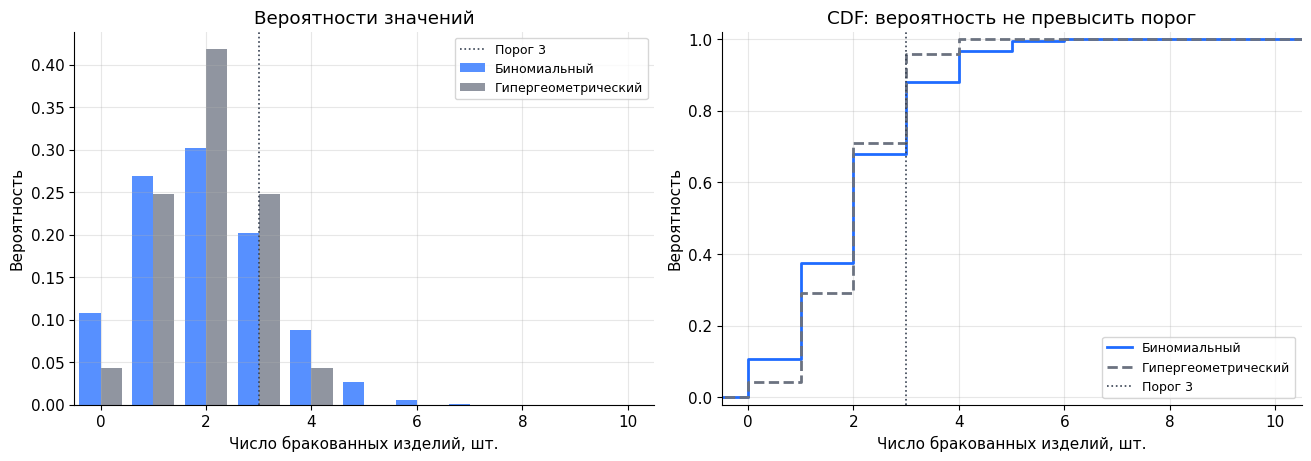

In [7]:
batch_laws = {"Биномиальный": stats.binom(n=10, p=0.2), "Гипергеометрический": stats.hypergeom(M= 20, n=4, N= 10)}
batch_results = []
for name in batch_laws:
    law = batch_laws[name]
    p95 = int(law.ppf(0.95))
    row = { "Модель": name, "E(X)": law.mean(), "Var(X)": law.var(), "P(X >= 3)": 1 - law.cdf(2), "P(X < 2)": law.cdf(1),"95-й перцентиль": p95}
    batch_results.append(row)
show_results(globals().get("batch_results"))
plot_laws(globals().get("batch_laws"), discrete=True, xlim=(-0.5, 10.5),
          xlabel="Число бракованных изделий, шт.", thresholds=(3,))

### 1.2. Эксперимент

Сгенерируйте по `SAMPLE_SIZE` наблюдений каждой модели с `random_state=rng`
и сохраните в словарь `batch_samples` с теми же именами моделей.
Найдите частоту события $X\ge3$ и 95-й перцентиль выборки и поставьте их рядом
с модельными значениями в таблице `batch_experiment`. Выборочный перцентиль
должен считаться по тому же правилу, что и квантиль дискретного закона.

**Структуры данных.**
- `batch_samples` — словарь с теми же ключами, что у законов; значение — массив NumPy из `SAMPLE_SIZE` наблюдений.
- `batch_experiment` — список словарей, как `batch_results`.

In [ ]:
# batch_samples = {"название модели": массив наблюдений, ...}
# batch_experiment = [{"Модель": ..., ...}, ...]


In [8]:

batch_samples = {}
for name in batch_laws:
    law = batch_laws[name]
    batch_samples[name] = law.rvs(size=SAMPLE_SIZE, random_state=rng)
batch_experiment = []
for name in batch_laws:
    law = batch_laws[name]
    sample = batch_samples[name]
    # выборка где X >= 3
    freq_3 = np.mean(sample >= 3)
    # 95-й перцентиль
    sample_p95 = int(np.percentile(sample, 95, method="inverted_cdf"))
    row = {"Модель": name,"P(X >= 3) модель": 1 - law.cdf(2), "Частота (X >= 3) выборка": freq_3, "95-й перцентиль модель": int(law.ppf(0.95)), "95-й перцентиль выборка": sample_p95 }
    batch_experiment.append(row)

,Модель,P(X >= 3) модель,Частота (X >= 3) выборка,95-й перцентиль модель,95-й перцентиль выборка
0,Биномиальный,0.32220,0.3288,4,4
1,Гипергеометрический,0.29102,0.2935,3,3


,Модель,Объём выборки,Среднее выборки,Дисперсия выборки (делим на n),Стандартное отклонение выборки
0,Биномиальный,10000,2.0284,1.61519,1.27090
1,Гипергеометрический,10000,2.0022,0.84980,0.92184


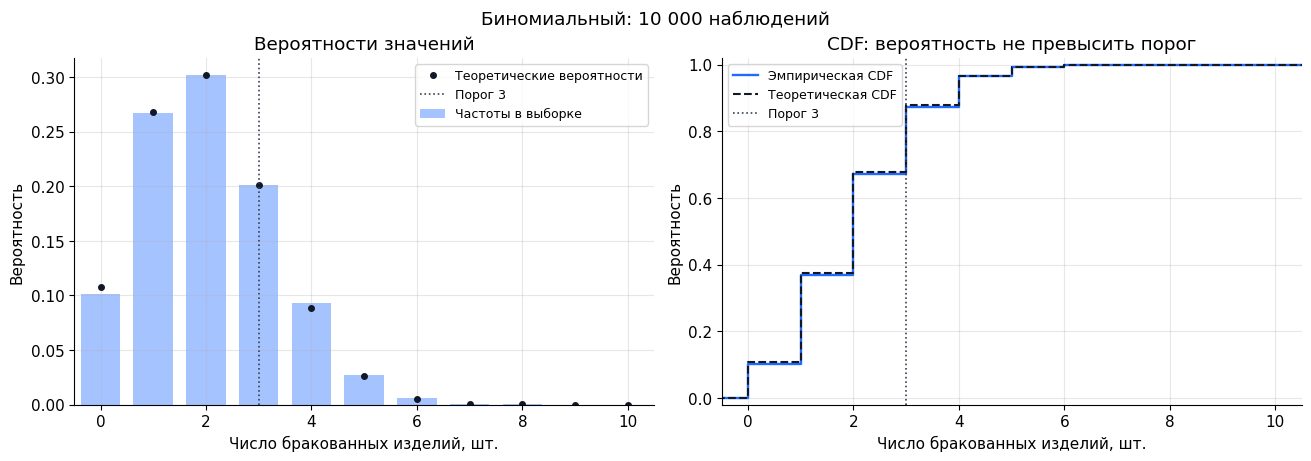

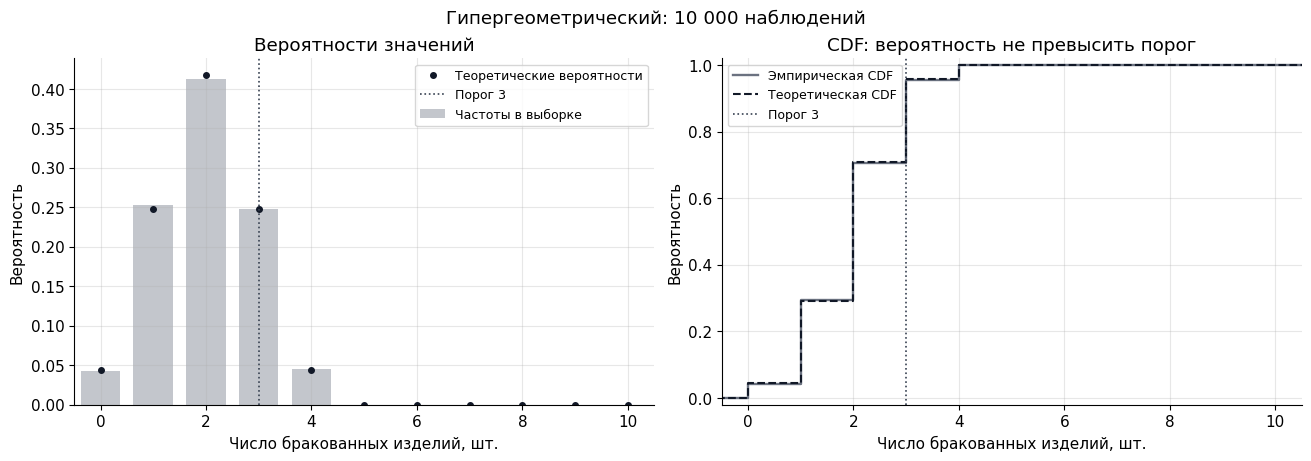

In [9]:
show_results(globals().get("batch_experiment"))
show_results(summarize_samples(globals().get("batch_samples")))
compare_samples(globals().get("batch_laws"), globals().get("batch_samples"),
                discrete=True, xlim=(-0.5, 10.5),
                xlabel="Число бракованных изделий, шт.", thresholds=(3,))

### 1.3. Ваш вывод

Почему ожидания совпали, а дисперсии различаются? Как выборка без возвращения
меняет неопределённость? Почему CDF в 95-м перцентиле не обязана быть ровно 0,95?
Объясните небольшое различие между частотой и вероятностью.
Почему у гипергеометрического закона $P(X<2)$ совпала с $P(X\ge3)$?

**Запишите 2–4 предложения:** … 1) потому что брак везде равен 0,2, но во второй задаче дисперсия меньше тк инфа о партия узнается больше и разброс уменьшается. 2) выборка уменьшает необеределенность из-за того что мы берем детали без возравщения, из-за этого дается больше инфы об остальныз деталях 3) величина дискретная, функция растет ступенями, и поэтому накопительная веростность будет больше 0.95, поэтому надо взять целое число, где как раз выйдет больше 0.95, потому что идеала не бывает 4) вероятность - для бесконечного числа опытов, по закону расписано, частота - это сам резульат на опыте, ограниченная выборка, поэтому могут быть различия в резудтатах, те частота как бы на практике определяется, а вероятность по закону. 5) ну наверное потому что получилась как симметрия данное мероприятие, тк проверяем половину партии на брак, а 4 из которых брак

## 2. Ошибки измерения: одинаковые характеристики, разные хвосты

**Документация:** [norm](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html), [uniform](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.uniform.html), [numpy.percentile](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html).

**Условие.** Ошибка первого прибора нормальна с ожиданием 0 мм и стандартным
отклонением 2 мм. Ошибка второго равномерна на $[-2\sqrt3;2\sqrt3]$ мм.
Нас интересует выход ошибки за пределы $\pm4$ мм.

**Заметка перед кодом — заполните.**

- Величина, единицы, возможные значения для двух приборов: … ошибки измерения в мм, 1 прибор от минус бесконечности до плюс бесконечности, а 2 прибор в условии вот с корнями [−23–√;23–√] (нормально не вставляется и не копируется)
- Параметры SciPy и их связь с условием: … 1 прибор мат ожидаение 0 и стандартным отклонением 2, 2 прибор здесь хитро, тк сама функция не задает интервал, а дает начальную точку и конечную ширину, и получается нижняя граница это минус 2 корня из 3, а ширина 4 корня из 3, тк по формуле это будет их разница
- Методы для вероятности выхода за две границы и квантилей: … например cdf() когда будет больше 4 мм выход, складываем вероятность левого хвоста cdf(-4) и правого хвоста 1 - cdf(4)
- Как считать квантили модели и перцентили выборки: … методом ppf(q), а выборочные перцентили np.percentile()

### 2.1. Анализ моделей

Создайте словарь `error_laws`. Для каждого закона найдите $E(X)$, $\mathrm{Var}(X)$, $\sigma(X)$,
$P(|X|>4)$, 95-й и 99-й перцентили. Соберите таблицу `error_results`.
Совпадают ли ожидания и дисперсии двух приборов? А вероятности выхода за допуск?

**Структуры данных.**
- `error_laws` — словарь: ключ — название модели (строка), значение — объект распределения SciPy с заданными параметрами.
- `error_results` — список словарей: один словарь на модель, ключи — названия столбцов (первый — `"Модель"`), значения — числа. Из него `show_results` строит таблицу.

In [ ]:
# error_laws = {"название модели": объект распределения, ...}
# error_results = [{"Модель": ..., ...}, ...]


In [10]:

error_laws = { "Нормальный прибор": stats.norm(loc=0, scale=2), "Равномерный прибор": stats.uniform(loc=-2 * np.sqrt(3), scale=4 * np.sqrt(3))}
error_results = []
for name in error_laws:
    law = error_laws[name]
    p_out = law.cdf(-4) + (1 - law.cdf(4))
    row = {"Модель": name, "E(X)": law.mean(), "Var(X)": law.var(),"P(|X|>4)": p_out, "95-й перцентиль": law.ppf(0.95), "99-й перцентиль": law.ppf(0.99)}
    error_results.append(row)

,Модель,E(X),Var(X),P(|X|>4),95-й перцентиль,99-й перцентиль
0,Нормальный прибор,0.0,4.0,0.0455,3.28971,4.65270
1,Равномерный прибор,0.0,4.0,0.0000,3.11769,3.39482


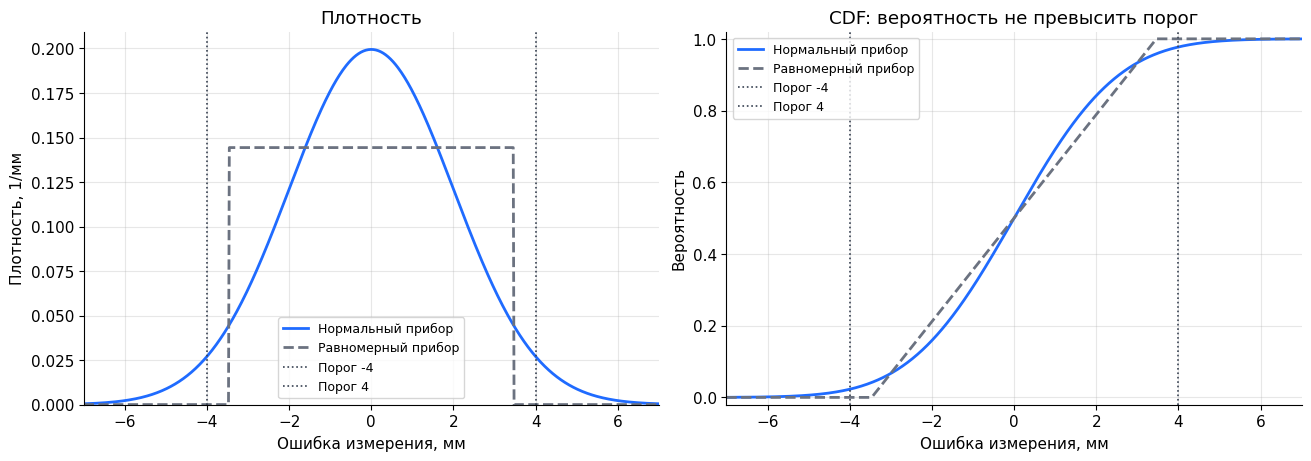

In [11]:
show_results(globals().get("error_results"))
plot_laws(globals().get("error_laws"), discrete=False, xlim=(-7, 7),
          xlabel="Ошибка измерения, мм", density_label="Плотность, 1/мм",
          thresholds=(-4, 4))

### 2.2. Эксперимент

Сгенерируйте по `SAMPLE_SIZE` ошибок каждого прибора в словарь `error_samples`.
Найдите частоту $|X|>4$, 95-й и 99-й перцентили выборок и сравните их с моделью
в таблице `error_experiment`.

**Структуры данных.**
- `error_samples` — словарь с теми же ключами, что у законов; значение — массив NumPy из `SAMPLE_SIZE` наблюдений.
- `error_experiment` — список словарей, как `error_results`.

In [ ]:
# error_samples = {"название модели": массив наблюдений, ...}
# error_experiment = [{"Модель": ..., ...}, ...]


In [12]:

error_samples = {}
for name in error_laws:
    law = error_laws[name]
    error_samples[name] = law.rvs(size=SAMPLE_SIZE, random_state=rng)
error_experiment = []
for name in error_laws:
    sample = error_samples[name]
    law = error_laws[name]
    freq_out = np.mean(np.abs(sample) > 4)
    row = { "Модель": name, "Частота (|X|>4) выборка": freq_out, "95-й перцентиль выборка": np.percentile(sample, 95), "99-й перцентиль выборка": np.percentile(sample, 99)}
    error_experiment.append(row)

,Модель,Частота (|X|>4) выборка,95-й перцентиль выборка,99-й перцентиль выборка
0,Нормальный прибор,0.0457,3.28157,4.56632
1,Равномерный прибор,0.0000,3.12488,3.39729


,Модель,Объём выборки,Среднее выборки,Дисперсия выборки (делим на n),Стандартное отклонение выборки
0,Нормальный прибор,10000,0.00202,3.96031,1.99005
1,Равномерный прибор,10000,0.01444,4.01648,2.00412


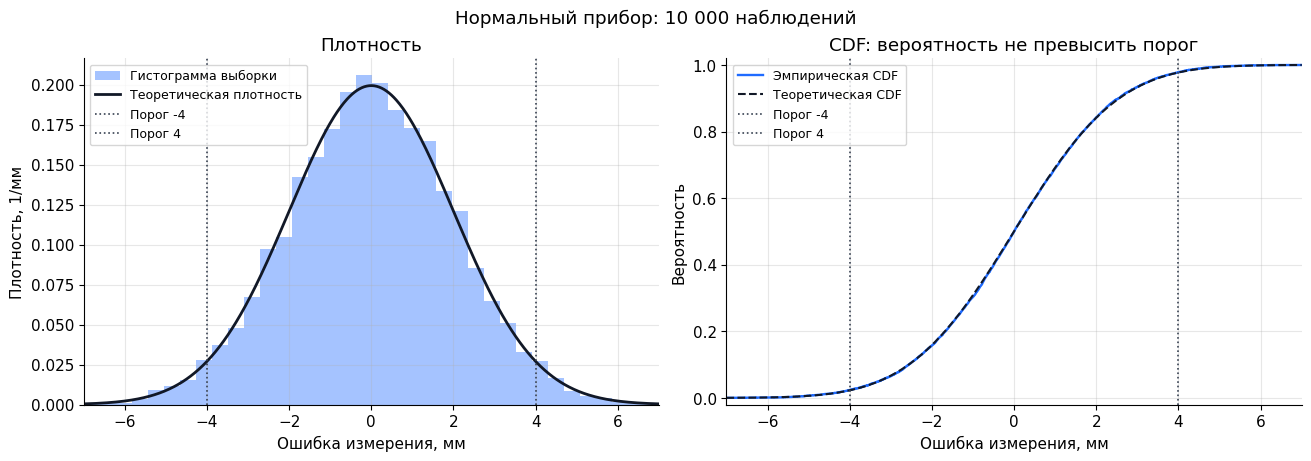

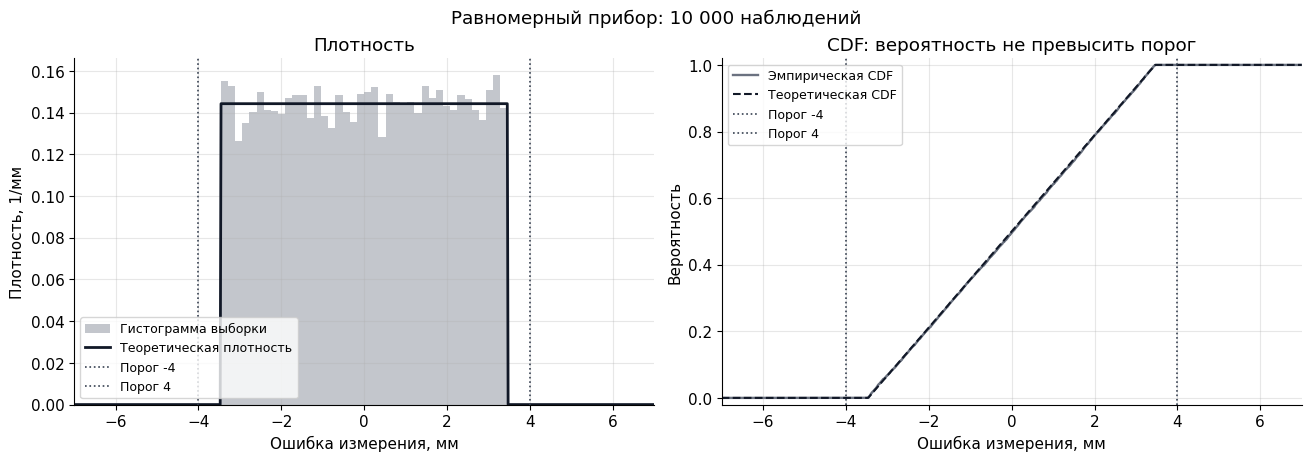

In [13]:
show_results(globals().get("error_experiment"))
show_results(summarize_samples(globals().get("error_samples")))
compare_samples(globals().get("error_laws"), globals().get("error_samples"),
                discrete=False, xlim=(-7, 7), xlabel="Ошибка измерения, мм",
                density_label="Плотность, 1/мм", thresholds=(-4, 4))

### 2.3. Ваш вывод

Достаточно ли одинаковых ожидания и дисперсии для одинакового риска больших ошибок?
Почему в одной выборке выходов за допуск может не быть вовсе?
Чем модельный перцентиль отличается от выборочного?

**Запишите 2–4 предложения:** … 1) нет, тк у них разные окончания 2) из-за рандома разброса данных 3) модельный тоже с формулой, значение из формулы распредления, а выборочный резульат по выбранным точкам

## 3. Срок службы: новое и уже работавшее устройство

**Документация:** [expon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html), [weibull_min](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.weibull_min.html), [numpy.percentile](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html).

**Условие.** У первого типа устройств $T$ имеет показательное распределение
с интенсивностью 0,01 в час. У второго — распределение Вейбулла с формой 2
и масштабом 100 часов. Сдвиг обеих моделей нулевой. Параметры заданы,
оценивать их по наблюдениям не нужно.

**Заметка перед кодом — заполните.**

- Величина, единицы и область возможных значений: … T= в часах срок слубы, овз: неотрицальные числа, так в часах измеряем
- Параметры SciPy для двух моделей: … 1 устройство: stats.expon(scale=100), потому что обратная величина интенсивности, тк 1:0.01=100, 2 устройство: stats.weibull_min(c=2, scale=100)
- Метод для вероятности проработать дольше порога: … ну вообще law.cdx(100) но нам надо узнать больше порога, поэтому обратную величину и поэтому 1-law.cdx(100)
- Уровень квантиля для замены до отказа 10% устройств и его смысл: … время, через которое выйдет из строя 10 процентов устройств

### 3.1. Анализ моделей

Создайте словарь `lifetime_laws`. Для каждого закона вычислите:

- $E(T)$, $\mathrm{Var}(T)$ и $\sigma(T)$;
- $P(T\le50)$ и $P(T>100)$;
- 10-й и 90-й перцентили;
- срок замены, к которому откажет не более 10% устройств, и вероятность отказа к нему;
- $P(T>150\mid T>50)$ — вероятность ещё 100 часов работы после уже отработанных 50.

Сравните последний результат с $P(T>100)$ для нового устройства. Выведите таблицу `lifetime_results`. Время измеряется в часах, дисперсия — в часах².

**Структуры данных.**
- `lifetime_laws` — словарь: ключ — название модели (строка), значение — объект распределения SciPy с заданными параметрами.
- `lifetime_results` — список словарей: один словарь на модель, ключи — названия столбцов (первый — `"Модель"`), значения — числа. Из него `show_results` строит таблицу.

In [ ]:
# lifetime_laws = {"название модели": объект распределения, ...}
# lifetime_results = [{"Модель": ..., ...}, ...]


In [ ]:

lifetime_laws = { "Показательное": stats.expon(scale=100), "Вейбулла": stats.weibull_min(c=2, scale=100)}
lifetime_results = []
for name in lifetime_laws:
    law = lifetime_laws[name]
    replace_time = law.ppf(0.10)
    p_more_150 = 1 - law.cdf(150)
    p_more_50 = 1 - law.cdf(50)
    p_cond = p_more_150 / p_more_50
    row = {"Модель": name,"E(T)": law.mean(),"Var(T)": law.var(),"P(T <= 50)": law.cdf(50),"P(T > 100)": 1 - law.cdf(100),"10-й перцентиль": law.ppf(0.10),"90-й перцентиль": law.ppf(0.90),"Срок замены": replace_time,"P(отказа к замене)": law.cdf(replace_time), "P(T > 150 | T > 50)": p_cond}
    lifetime_results.append(row)

In [ ]:
show_results(globals().get("lifetime_results"))
plot_laws(globals().get("lifetime_laws"), discrete=False, xlim=(0, 500),
          xlabel="Срок службы, ч", density_label="Плотность, 1/ч",
          thresholds=(50, 100))

### 3.2. Эксперимент

Сгенерируйте по `SAMPLE_SIZE` сроков службы каждого типа в словарь `lifetime_samples`.
Найдите 10-й и 90-й перцентили выборок и частоты трёх событий: отказ к 50 часам,
работа дольше 100 часов, отказ к **модельному** сроку замены (таблица `lifetime_experiment`).

Оцените по выборке и условную вероятность $P(T>150\mid T>50)$. Укажите, по скольким
наблюдениям она посчитана, и сравните с моделью (таблица `lifetime_conditional_experiment`).

**Структуры данных.**
- `lifetime_samples` — словарь с теми же ключами, что у законов; значение — массив NumPy из `SAMPLE_SIZE` наблюдений.
- `lifetime_experiment` и `lifetime_conditional_experiment` — списки словарей, по одному на модель.

In [ ]:
# lifetime_samples = {"название модели": массив наблюдений, ...}
# lifetime_experiment = [{"Модель": ..., ...}, ...]
# lifetime_conditional_experiment = [{"Модель": ..., ...}, ...]


In [ ]:
lifetime_samples = {name: lifetime_laws[name].rvs(size=SAMPLE_SIZE, random_state=rng) for name in lifetime_laws}
lifetime_experiment = []
lifetime_conditional_experiment = []
for name in lifetime_laws:
    law = lifetime_laws[name]
    sample = lifetime_samples[name]
    replace_time = law.ppf(0.10)
    lifetime_experiment.append({ "Модель": name, "10-й перцентиль выборка": np.percentile(sample, 10), "90-й перцентиль выборка": np.percentile(sample, 90), "Частота отказа к 50 ч": np.mean(sample <= 50),"Частота работы > 100 ч": np.mean(sample > 100), "Частота отказа к сроку замены": np.mean(sample <= replace_time)})
    survived = sample[sample > 50]
    lifetime_conditional_experiment.append({ "Модель": name, "Выживших (>50ч)": len(survived), "Условная частота (выборка)": np.mean(survived > 150), "Условная вероятность (модель)": (1 - law.cdf(150)) / (1 - law.cdf(50))})

In [ ]:
show_results(globals().get("lifetime_experiment"))
show_results(globals().get("lifetime_conditional_experiment"))
show_results(summarize_samples(globals().get("lifetime_samples")))
compare_samples(globals().get("lifetime_laws"), globals().get("lifetime_samples"),
                discrete=False, xlim=(0, 500), xlabel="Срок службы, ч",
                density_label="Плотность, 1/ч", thresholds=(50, 100))

### 3.3. Ваш вывод

Что означает 10-й перцентиль срока службы? Что случится, если заменить его 90-м?
Как уже отработанные 50 часов меняют вероятность следующих 100 часов работы?
Почему при оценке условной частоты меняется знаменатель?

**Запишите 2–4 предложения:** … 1) время к которому выйдут 10 процентов приборов, 2) время к которому выйдет 90 процентов приборов, ну просто тупо, все сломается 3) для первого прибора никак, хоть еще 100 отработает, а для второго эксперимента в самой модели есть фактор износа, ну и просто ниже будет вероятность прожить до 100 часов 4) тк условная вероятность расчитывается по выжившим устройствам, поэтому меняется, приборы же ломаются, значит знаменаетль тоже

## 4. Найдите ошибки

В каждой строке ниже есть ошибка: код запускается, но отвечает не на тот вопрос.
Для каждой строки найдите ошибку, исправьте вызов и в комментарии одной фразой объясните, что было не так.
Сначала предскажите правильный ответ, затем запустите.

1. $X\sim N$ с $E(X)=40$ и $\mathrm{Var}(X)=100$. Нужна дисперсия, чтобы проверить параметры.
2. Диаметр детали $X\sim N(20;\,0{,}1^2)$, мм. Нужна $P(X=20)$.
3. $N$ — число заявок за час, закон Пуассона с $\lambda=3$. Нужна $F(2)=P(N<2)$.
4. $X\sim N(0;1)$. Нужен 95-й перцентиль.
5. Заявки приходят с интенсивностью 3 в час. Нужно среднее время ожидания заявки в **минутах**.
6. $X$ равномерна на отрезке $[2;7]$ (задача 6.2 методички). Нужно $E(X)$.

In [ ]:
count = stats.poisson(mu=3)  # число заявок за час

print("1. Var(X):", stats.norm(loc=40, scale=10).var())
print("2. P(X = 20):", stats.norm(loc=20, scale=0.1).pdf(20))
print("3. P(N < 2):", count.cdf(1))
print("4. 95-й перцентиль:", stats.norm().ppf(0.95))
print("5. E(T), мин:", stats.expon(scale=20).mean())
print("6. E(X):", stats.uniform(loc=2, scale=5).mean())

**Ваши объяснения (по одной фразе на строку):** 1 — … потому шо надо передавать корень из числа(стандартное отклоение), а не дисперсию ; 2 — все норм ; 3 —строго меньше 2, 2 не входит, пишем 1; 4 — перцентиль пишется не как процент, а как десятичная дробь; 5 —  интервал 20, тк за час (60 минут) приходят 3 заявки; 6 — интервал нужен, а не граница, т.е 7-2=5

## 5. Самостоятельный перенос: допуск на размер

**Условие.** Размер изделия $X$ распределён нормально: $E(X)=100$ мм,
$\mathrm{Var}(X)=3^2$ мм². Допустимы размеры от 94 до 106 мм включительно.

1. Найдите вероятность выхода за допуск.
2. Постройте симметричный относительно ожидания интервал, содержащий 99% значений.
   Объясните, как вероятность распределяется между хвостами.
3. Проверьте один из результатов симуляцией и объясните расхождение с теорией.


In [14]:
# Ваш код
law = stats.norm(loc=100, scale=3)
p_out = 1 - (law.cdf(106) - law.cdf(94))
print("Выход за допуск (теория):", p_out)
print("Интервал 99%:", law.ppf(0.005), law.ppf(0.995))
sample = law.rvs(size=10000, random_state=rng)
freq_out = np.mean((sample < 94) | (sample > 106))
print("Выход за допуск (выборка):", freq_out)

Выход за допуск (теория): 0.04550026389635842
Интервал 99%: 92.2725120893533 107.7274879106467
Выход за допуск (выборка): 0.0453


**Ваш ответ:** вероятность выхода за допуск — 0.0455; интервал — [92,27;107,72]
вероятности в левом и правом хвостах — по 0.005; результат симуляции и его смысл — частота выходит за допуск по выборке, поэтому близко к теорит.

## 6. Собственная шпаргалка и самопроверка

Заполните таблицу после выполнения лабораторий. Смысл метода должен быть понятен
без кода: для вероятности обязательно укажите знак неравенства.

| Вопрос | Метод | Смысл аргументов | Что возвращается | Ссылка на определение |
|---|---|---|---|---|
| Ожидание, дисперсия, стандартное отклонение | .mean() .var() .std() | не нужны | E(x) Var(x) sigma(X) |  |
| Вероятность отдельного значения / плотность | .pmf(x) .pdf(x) | просто значения любые по условию или рандом | P(X=x) | … |
| Вероятность слева от порога, $\le$ и $<$ для целочисленной величины | .cdf(x) .cdf(1-x) | накопленная вероятность что величина не привысит порог | x - порог, x-1 - порог для строгого неравенста | … |
| Вероятность справа от порога | 1 - law.cdf(x) | x- нижний порог значения | вероятность строго превысить порог | … |
| Квантиль модели | .ppf(q) | q- уровень вероятности  | порог для x, типа P(X<=x)=q | … |
| Случайная выборка | .rvs(size=n, random_state=rng) | size - обьем выборки random_state- зерно выборки | массив из n по закону зерна | … |
| Перцентиль наблюдений | np.percentile(sample, p) | sample - массив данных p- процент | любое значение, ниже котрого лежат p  | … |

Перед завершением проверьте:

- Для каждой лаборатории есть параметры, расчётная таблица, графики, симуляция и вывод.
- Вероятности лежат в $[0;1]$, дисперсии неотрицательны, единицы подписаны.
- Для дискретного события явно учтено включение границы.
- 95-й перцентиль модели и симметричный 95%-й интервал не перепутаны.
- Условная частота использует правильную подвыборку и указанный знаменатель.
- Перезапуск среды и выполнение сверху вниз воспроизводят ваш анализ.

Если остались незавершённые расчёты, закончите их дома. По желанию повторите одну
симуляцию с другим зерном: теоретические значения сохранятся, выборочные немного изменятся.
Не подбирайте зерно ради точного совпадения. Совпадение графиков симуляции и модели
здесь проверяет работу с заданным законом, а не доказывает пригодность закона реальным данным.